# Buscando la mejor red con GridSearchCV

|                |   |
:----------------|---|
| **Nombre**     | Carlos Enrique Nieves Ochoa |
| **Fecha**      | 19 de octubre de 2026 |
| **Expediente** | 758210 |

## ¿Qué problema estamos resolviendo?

Cuando eliges hiperparámetros en realidad estás resolviendo un problema de optimización: tienes varias opciones para probar y quieres quedarte con la que da el mejor resultado. Solo hay que tener claras tres cosas: qué voy a mover (los hiperparámetros), entre qué valores (la rejilla) y con qué lo voy a calificar (la métrica).

**El ejemplo del pizarrón.** Con una SVM se probaron 3 valores de $\gamma$ y 3 de $C$ (0.1, 1 y 10). Si haces todas las combinaciones te salen 9 modelos, cada uno con su calificación:

| Modelo | $\gamma$ | $C$ | Calificación |
| :- | :-: | :-: | :-: |
| m1 | 0.1 | 0.1 | 0.40 |
| m2 | 0.1 | 1 | 0.42 |
| m3 | 0.1 | 10 | 0.38 |
| m4 | 1 | 0.1 | 0.45 |
| **m5** | **1** | **1** | **0.52** |
| m6 | 1 | 10 | 0.37 |
| m7 | 10 | 0.1 | 0.41 |
| m8 | 10 | 1 | 0.42 |
| m9 | 10 | 10 | 0.41 |

O sea, buscamos

$$\max_{\gamma,\, C} \; \text{calificación}(\gamma, C) \qquad \text{con } \gamma, C \in \{0.1,\ 1,\ 10\}$$

y gana m5 ($\gamma = 1$, $C = 1$) porque es el que saca más. Esto es justo lo que hizo `GridSearchCV` en la Ingeniería inversa: probó las 16 combinaciones de `svc__C` y `svc__gamma` y nos dio la mejor en `best_params_`.

**¿Y por qué separar train y test si ya hay K-Fold?** Porque hacen cosas distintas. El K-Fold, que corre solo con train, es el que califica cada combinación para escoger la mejor. El test lo guardo y lo uso una sola vez al final: como el ganador fue elegido entre muchísimos modelos, su calificación de K-Fold suele salir un poco inflada (algunos ganan en parte por suerte), y el test me dice qué tan bien le va de verdad con datos que nunca vio.

**Lo que hay que hacer.** Con el dataset de enfermedades del corazón voy a usar un perceptrón con 3 capas ocultas y buscar cuántas neuronas poner en cada una:

- Capa 1: de 5 a 15 neuronas
- Capa 2: de 10 a 20 neuronas
- Capa 3: de 5 a 10 neuronas

Eso da $11 \times 11 \times 6 = 726$ redes distintas. A cada una la califico con el AUC promedio de un K-Fold con $K = 5$, y me quedo con la que saque más:

$$\max_{c_1,\, c_2,\, c_3} \; \frac{1}{5} \sum_{k=1}^{5} AUC_k(c_1, c_2, c_3)$$

donde $c_1, c_2, c_3$ son las neuronas de cada capa. Al final reviso el AUC de test de la ganadora.

In [1]:
# Lo que voy a necesitar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

**1. Cargar los datos**

Cargo el dataset y le echo un ojo a las primeras filas para ver con qué estoy trabajando.

In [2]:
df = pd.read_csv("Heart Prediction Quantum Dataset (1).csv")
print(df.shape)
df.head()

(500, 6)


,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
0,68,Hombre,105.00,191,107,1
1,58,Mujer,97.00,249,89,0
2,44,Mujer,93.00,190,82,1
3,72,Hombre,93.00,183,101,1
4,37,Mujer,145.00,166,103,1


Son 500 pacientes y 6 columnas: edad, género, presión arterial, colesterol, ritmo cardiaco y si tiene o no la enfermedad (`HeartDisease`, 1 = sí). Ya desde aquí se nota que `Gender` trae espacios raros ("Hombre   "), así que toca revisarlo bien.

**2. Revisar el dataset**

Reviso qué tipo de dato tiene cada columna, si falta algo, si hay filas repetidas y cómo vienen escritas las categorías.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Age            500 non-null    int64 
 1   Gender         500 non-null    object
 2   BloodPressure  500 non-null    object
 3   Cholesterol    500 non-null    int64 
 4   HeartRate      500 non-null    int64 
 5   HeartDisease   500 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 23.6+ KB


In [4]:
# ¿Falta algo o hay filas repetidas?
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

Age              0
Gender           0
BloodPressure    0
Cholesterol      0
HeartRate        0
HeartDisease     0
dtype: int64
Duplicados: 0


In [5]:
# Cuántos enfermos hay y cómo viene escrito Gender
print(df["HeartDisease"].value_counts())
print(df["Gender"].value_counts())

HeartDisease
1    300
0    200
Name: count, dtype: int64
Gender
Mujer        208
Hombre       149
Hombre        66
mujer         43
Hombre}       18
MUJER          7
Mujer{         5
MUjer          3
ombre          1
Name: count, dtype: int64


Son 500 pacientes, sin datos faltantes ni filas repetidas. Hay 300 con enfermedad y 200 sin ella, así que las clases no están parejas; por eso el AUC me sirve, porque no depende del umbral. `BloodPressure` está como texto porque algunos valores traen coma en lugar de punto, y `Gender` está escrito de mil formas (con mayúsculas, espacios, llaves y hasta un "ombre").

**3. Limpiar los datos**

Arreglo las comas de `BloodPressure`, limpio `Gender` y al final lo dejo como 1 para hombre y 0 para mujer.

In [6]:
# Cambio la coma por punto para que sea número
df["BloodPressure"] = df["BloodPressure"].str.replace(",", ".", regex=False)
df["BloodPressure"] = df["BloodPressure"].astype(float)

# Todo a minúsculas, fuera espacios y llaves, y arreglo el "ombre"
gen = df["Gender"].str.lower()
gen = gen.str.rstrip(" }{")
gen.loc[gen == "ombre"] = "hombre"
df["Gender"] = gen.map({"hombre": 1, "mujer": 0})

print(df["Gender"].value_counts())
df.describe()

Gender
0    266
1    234
Name: count, dtype: int64


,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000
mean,54.864000,0.468000,132.874000,221.50000,88.766000,0.600000
std,14.315004,0.499475,26.418516,43.86363,17.417289,0.490389
min,30.000000,0.000000,90.000000,150.00000,60.000000,0.000000
25%,43.000000,0.000000,111.000000,183.75000,73.000000,0.000000
50%,55.000000,0.000000,132.000000,221.00000,89.000000,1.000000
75%,66.250000,1.000000,155.000000,258.00000,104.000000,1.000000
max,79.000000,1.000000,179.000000,299.00000,119.000000,1.000000


Con la limpieza ya todo es numérico. Quedaron 266 mujeres (0) y 234 hombres (1), o sea que ningún registro se perdió en el camino. En el resumen se ve que las variables están en escalas muy distintas: el colesterol anda entre 150 y 299 mientras que la edad va de 30 a 79. Por eso hay que escalarlas, porque a la red le cuesta mucho aprender si una variable es mucho más grande que las otras. También se ve que el 60 % de los pacientes tiene la enfermedad (la media de `HeartDisease` es 0.6).

**4. Separar los datos**

Separo `X` y `y`, y luego dejo más o menos el 75% para entrenar y el 25% para probar, con `random_state=42` como lo vimos en Ingeniería inversa.

In [7]:
X = df.drop(columns=["HeartDisease"])
y = df["HeartDisease"]

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=42)
print(Xtrain.shape, Xtest.shape)

(375, 5) (125, 5)


Quedaron 375 pacientes para entrenar y 125 para probar. Los 375 de train son los que usa el K-Fold para escoger la red; los 125 de test no los toco hasta el final.

**5. Armar el modelo**

Escalo las columnas numéricas y dejo `Gender` tal cual, porque ya es 0 y 1. Meto todo junto con el perceptrón en un pipeline para que el escalamiento se haga dentro de cada fold y no se cuele información de los datos de validación.

In [8]:
numerical_cols = ["Age", "BloodPressure", "Cholesterol", "HeartRate"]
boolean_cols = ["Gender"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("bool", "passthrough", boolean_cols)
    ],
    remainder="drop"
)

mlp = MLPClassifier(max_iter=500, random_state=42)
model = make_pipeline(preprocessor, mlp)

Aquí todavía no se entrena nada, solo dejo listo el "molde": primero el escalamiento y luego la red. Dejé `max_iter=500` para darle más vueltas a la red que las 200 que trae por defecto.

**6. Armar la rejilla**

Con tres ciclos armo todas las combinaciones de neuronas que pide el ejercicio. Cada tupla, como `(5, 10, 5)`, es una red distinta para probar.

In [9]:
capas = []

for c1 in range(5, 16):
    for c2 in range(10, 21):
        for c3 in range(5, 11):
            capas.append((c1, c2, c3))

print(len(capas))
print(capas[:3])

param_grid = {"mlpclassifier__hidden_layer_sizes": capas}

726
[(5, 10, 5), (5, 10, 6), (5, 10, 7)]


Salieron las 726 redes que esperaba, desde `(5, 10, 5)` hasta `(15, 20, 10)`. El nombre `mlpclassifier__hidden_layer_sizes` le dice a `GridSearchCV` que cambie las capas de la parte del pipeline que se llama `mlpclassifier`, igual que `svc__C` en la Ingeniería inversa.

**7. Buscar la mejor red**

Aquí `GridSearchCV` hace todo el trabajo pesado. Con `scoring="roc_auc"` le digo que califique con el AUC y con `cv=5` que use un K-Fold de 5. Como cada una de las 726 redes se entrena 5 veces y son 3,630 entrenamientos. Al final `best_params_` me dice la red ganadora y `best_score_` su AUC promedio.

In [10]:
grid = GridSearchCV(model, param_grid, scoring="roc_auc", cv=5)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

c:\Users\carlo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


CPU times: total: 21min 21s
Wall time: 22min 16s
{'mlpclassifier__hidden_layer_sizes': (7, 15, 10)}
0.863079793436615


La ganadora fue la red con **7, 15 y 10 neuronas**, con un AUC promedio de **0.863** en el K-Fold. Tardó un buen rato porque fueron más de 3,600 entrenamientos. El aviso de abajo dice que la red no terminó de converger en 500 iteraciones; no quiere decir que esté mal, solo que todavía podía moverse un poco. Algo curioso es que la mejor red no es la más grande: tener más neuronas no garantiza un mejor resultado.

**8. Probar con test**

Tomo la red ganadora, que `GridSearchCV` ya volvió a entrenar con todo train, y veo qué AUC saca con los datos de prueba.

In [11]:
model = grid.best_estimator_

prob = model.predict_proba(Xtest)[:, 1]
yfit = (prob >= 0.5).astype(int)

auc = roc_auc_score(ytest, prob)
print("AUC de test:", auc)

AUC de test: 0.8078961314255433


Con los datos de prueba el AUC bajó a **0.808**. Es normal que baje: la red se escogió por ser la mejor de 726 en el K-Fold, y parte de esa ventaja fue suerte. Aun así, 0.81 está bastante bien; quiere decir que si tomo un paciente enfermo y uno sano, la red le da más probabilidad de estar enfermo al correcto como 8 de cada 10 veces.

**9. Reporte y matriz de confusión**

Veo la precisión, el recall y el F1 de cada clase, y en la matriz cuántos pacientes clasificó bien y en cuáles se equivocó.

In [12]:
print(classification_report(ytest, yfit, target_names=["Sin enfermedad", "Con enfermedad"]))

                precision    recall  f1-score   support

Sin enfermedad       0.72      0.71      0.71        51
Con enfermedad       0.80      0.81      0.81        74

      accuracy                           0.77       125
     macro avg       0.76      0.76      0.76       125
  weighted avg       0.77      0.77      0.77       125



- **Con enfermedad:** de los 74 enfermos detecta al 81 % (recall), y cuando dice "enfermo" acierta el 80 % de las veces (precisión).
- **Sin enfermedad:** de los 51 sanos reconoce al 71 %; al resto los marca como enfermos sin estarlo.
- **Accuracy de 0.77:** acierta en 96 de los 125 pacientes.

A la red le va mejor con los enfermos, seguramente porque había más de ellos para aprender (300 contra 200).

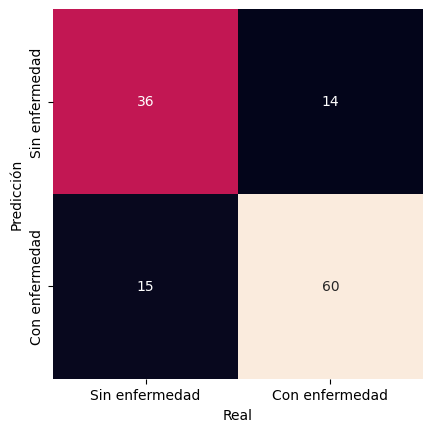

In [13]:
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt="d", cbar=False,
            xticklabels=["Sin enfermedad", "Con enfermedad"],
            yticklabels=["Sin enfermedad", "Con enfermedad"])
plt.xlabel("Real")
plt.ylabel("Predicción")
plt.show()

La diagonal son los aciertos: 36 sanos y 60 enfermos bien clasificados. Los errores son 15 sanos que marcó como enfermos y 14 enfermos que se le pasaron. Esos 14 son los que más preocupan, porque son personas enfermas a las que el modelo les diría que están bien.